In [4]:
pip install yfinance statsmodels pandas matplotlib

Note: you may need to restart the kernel to use updated packages.


In [5]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller, acf, pacf
from statsmodels.tsa.holtwinters import SimpleExpSmoothing, ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_squared_error, mean_absolute_error
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

In [6]:
#  LOAD TIME SERIES
TICKER = "AAPL"           # change to any ticker in your screener
START  = "2020-01-01"
END    = "2025-12-31"

def load_prices(ticker, start, end):
    try:
        import yfinance as yf
        df = yf.download(ticker, start=start, end=end,
                         auto_adjust=True, progress=False)
        if df.empty:
            raise ValueError("Empty download")
        s = df["Close"].squeeze()
        s.name = ticker
        print(f"Downloaded {len(s)} real trading days for {ticker}")
        return s
    except Exception as e:
        print(f"yfinance failed ({e}). Falling back to synthetic series.")
        idx = pd.bdate_range(start, end)
        trend = np.linspace(100, 180, len(idx))
        seasonal = 8 * np.sin(2 * np.pi * np.arange(len(idx)) / 252)
        noise = np.random.normal(0, 3, len(idx))
        return pd.Series(trend + seasonal + noise, index=idx, name=ticker)

series = load_prices(TICKER, START, END)
series.index = pd.to_datetime(series.index)
print(f"Range: {series.index.min().date()} → {series.index.max().date()}")
print(series.head())

Downloaded 1507 real trading days for AAPL
Range: 2020-01-02 → 2025-12-30
Date
2020-01-02    72.271530
2020-01-03    71.568893
2020-01-06    72.139183
2020-01-07    71.799911
2020-01-08    72.954895
Name: AAPL, dtype: float64


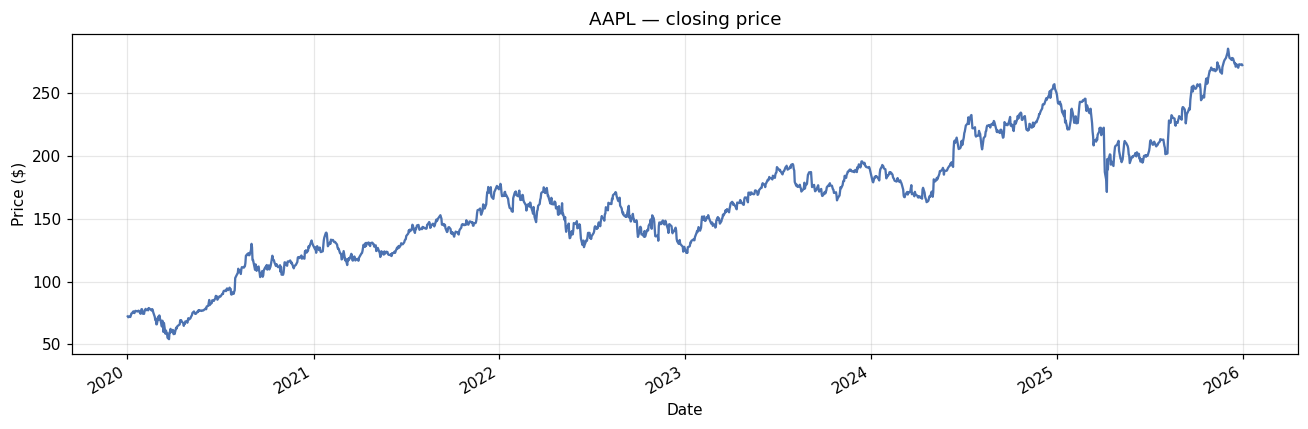

In [7]:
# PLOT RAW SERIES
fig, ax = plt.subplots(figsize=(12, 4))
series.plot(ax=ax, color="#4C72B0")
ax.set_title(f"{TICKER} — closing price")
ax.set_xlabel("Date"); ax.set_ylabel("Price ($)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ts_raw.png", bbox_inches="tight")
plt.show()

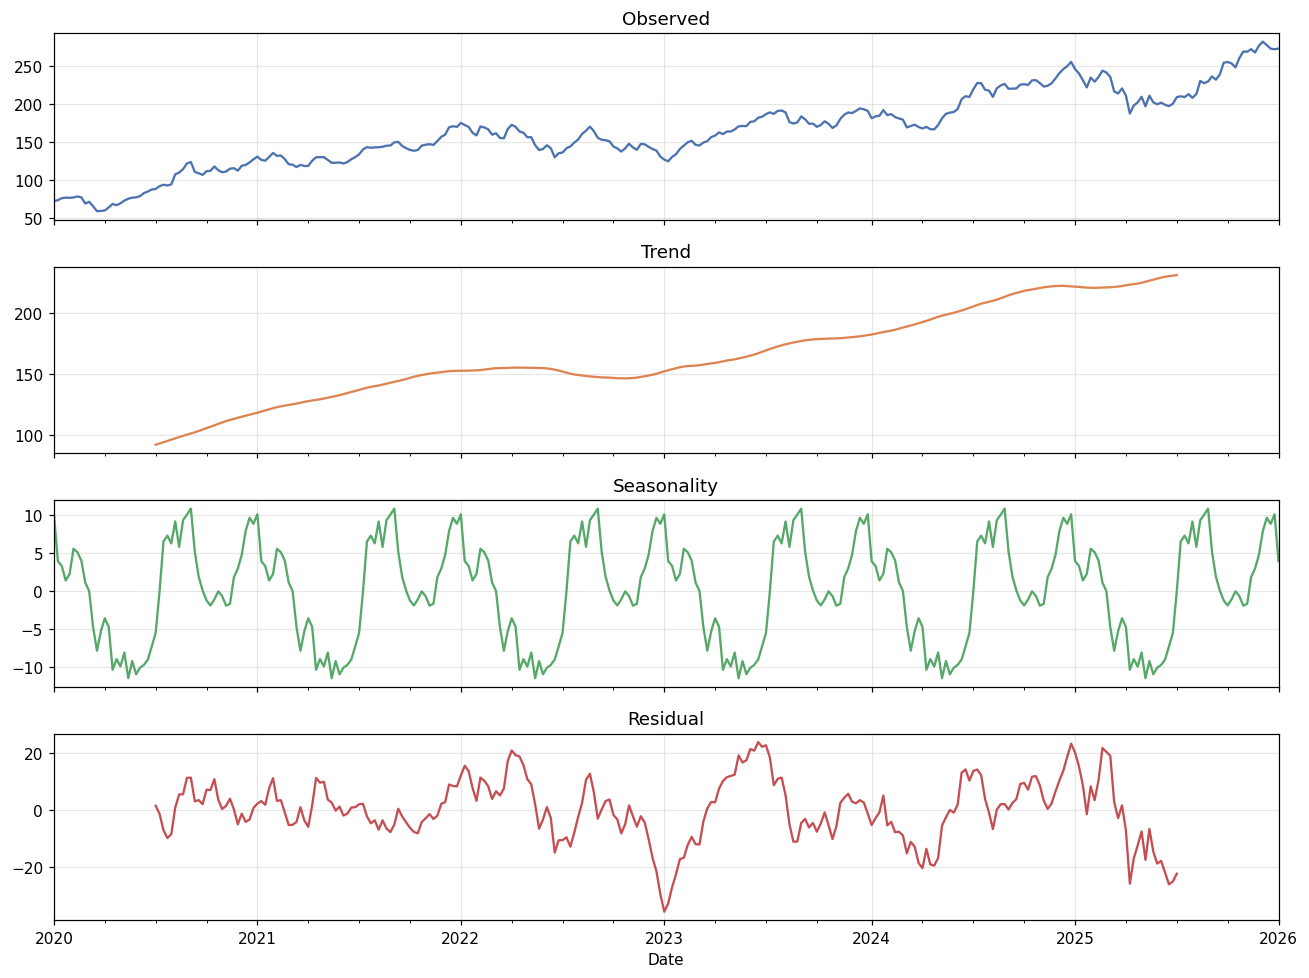

Component variances:
 trend_var       1315.935
seasonal_var      44.010
resid_var        118.689
dtype: float64
Residual share: 8.0%


In [8]:
# DECOMPOSITION — trend / seasonality / residual
# Use weekly-averaged series to make the 252-day seasonality legible
weekly = series.resample("W").mean().dropna()

decomp = seasonal_decompose(weekly, model="additive", period=52)

fig, axes = plt.subplots(4, 1, figsize=(12, 9), sharex=True)
weekly.plot(ax=axes[0], color="#4C72B0");   axes[0].set_title("Observed")
decomp.trend.plot(ax=axes[1], color="#DD8452");    axes[1].set_title("Trend")
decomp.seasonal.plot(ax=axes[2], color="#55A868"); axes[2].set_title("Seasonality")
decomp.resid.plot(ax=axes[3], color="#C44E52");    axes[3].set_title("Residual")
for a in axes: a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ts_decomposition.png", bbox_inches="tight")
plt.show()

# Quantify how much each component contributes
var_ratio = pd.Series({
    "trend_var":    decomp.trend.var(),
    "seasonal_var": decomp.seasonal.var(),
    "resid_var":    decomp.resid.var(),
})
print("Component variances:\n", var_ratio.round(3))
print(f"Residual share: {var_ratio['resid_var']/var_ratio.sum():.1%}")

Augmented Dickey-Fuller tests:
   raw price                      ADF=  -0.895  p=0.7896  → NON-stationary
   1st difference                 ADF= -38.071  p=0.0000  → stationary
   log 1st difference             ADF= -13.003  p=0.0000  → stationary


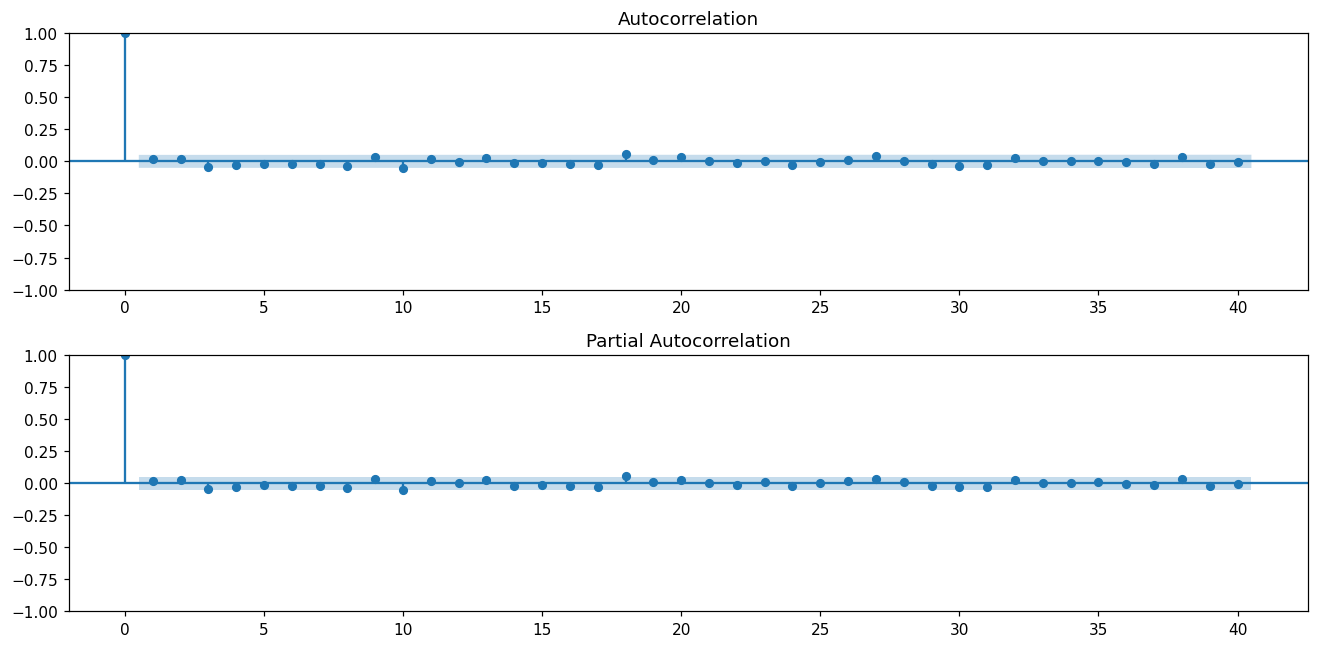

In [9]:
# STATIONARITY TESTS
def adf_report(s, label):
    result = adfuller(s.dropna(), autolag="AIC")
    stat, pval = result[0], result[1]
    verdict = "stationary" if pval < 0.05 else "NON-stationary"
    print(f"   {label:<30} ADF={stat:>8.3f}  p={pval:>6.4f}  → {verdict}")
    return pval

print("Augmented Dickey-Fuller tests:")
adf_report(series, "raw price")
adf_report(series.diff(), "1st difference")
adf_report(np.log(series).diff(), "log 1st difference")

# ACF / PACF to guide ARIMA order
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
plot_acf(series.diff().dropna(),  lags=40, ax=axes[0])
plot_pacf(series.diff().dropna(), lags=40, ax=axes[1])
plt.tight_layout()
plt.savefig("ts_acf_pacf.png", bbox_inches="tight")
plt.show()

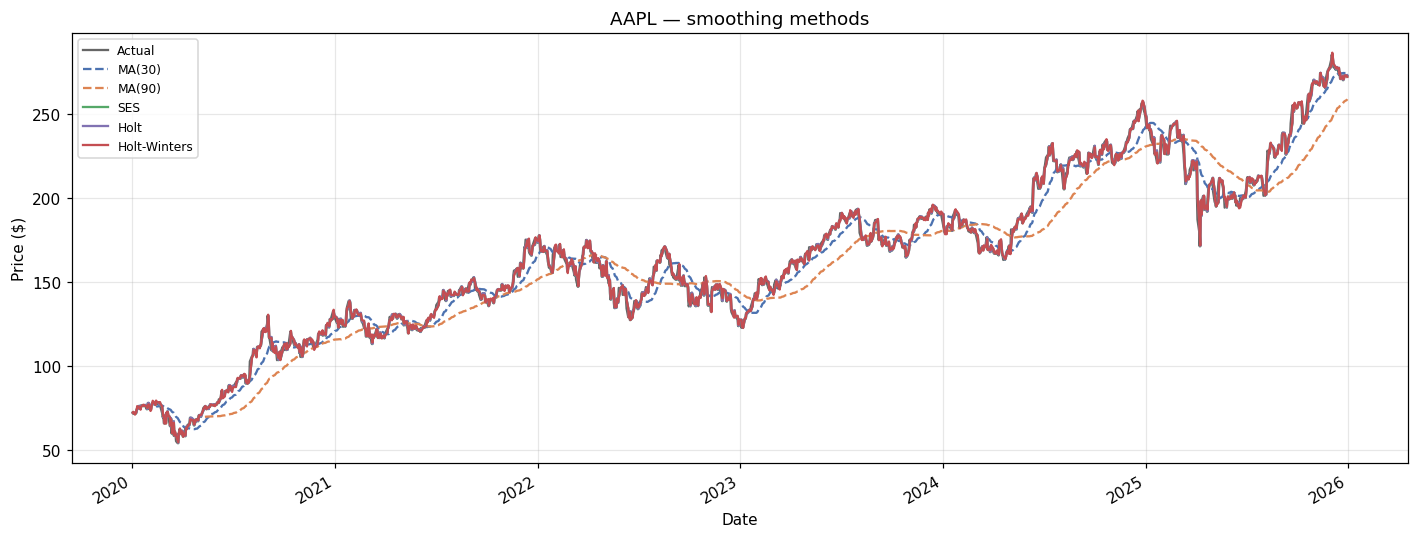

In [10]:
#MOVING AVERAGE & EXPONENTIAL SMOOTHING
# Rolling mean (moving average)
ma_30 = series.rolling(window=30).mean()
ma_90 = series.rolling(window=90).mean()

# Simple Exponential Smoothing (no trend, no seasonality)
ses = SimpleExpSmoothing(series).fit(optimized=True)

# Holt's linear (trend, no seasonality)
holt = ExponentialSmoothing(series, trend="add", seasonal=None).fit(optimized=True)

# Holt-Winters (trend + seasonality) — needs at least 2 full cycles
hw = ExponentialSmoothing(
    series, trend="add", seasonal="add",
    seasonal_periods=52 if len(series) > 104 else 5
).fit(optimized=True)

fig, ax = plt.subplots(figsize=(13, 5))
series.plot(ax=ax, label="Actual",   color="black", alpha=0.6)
ma_30.plot(ax=ax, label="MA(30)",    color="#4C72B0", ls="--")
ma_90.plot(ax=ax, label="MA(90)",    color="#DD8452", ls="--")
ses.fittedvalues.plot(ax=ax, label="SES",  color="#55A868")
holt.fittedvalues.plot(ax=ax, label="Holt", color="#8172B2")
hw.fittedvalues.plot(ax=ax,   label="Holt-Winters", color="#C44E52")
ax.set_title(f"{TICKER} — smoothing methods")
ax.set_xlabel("Date"); ax.set_ylabel("Price ($)")
ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ts_smoothing.png", bbox_inches="tight")
plt.show()

In [11]:
# TRAIN / TEST SPLIT (chronological — never shuffle!)
HORIZON = 60                      # forecast last 60 trading days
train, test = series[:-HORIZON], series[-HORIZON:]

print(f"Train: {len(train)} days  |  Test: {len(test)} days")

Train: 1447 days  |  Test: 60 days


In [12]:
#FIT MODELS ON TRAIN, FORECAST TEST
forecasts = {}

# Simple Exponential Smoothing
ses_fit = SimpleExpSmoothing(train).fit(optimized=True)
forecasts["SES"] = ses_fit.forecast(len(test))

# Holt
holt_fit = ExponentialSmoothing(train, trend="add").fit(optimized=True)
forecasts["Holt"] = holt_fit.forecast(len(test))

# Holt-Winters
try:
    hw_fit = ExponentialSmoothing(
        train, trend="add", seasonal="add",
        seasonal_periods=52 if len(train) > 104 else 5
    ).fit(optimized=True)
    forecasts["Holt-Winters"] = hw_fit.forecast(len(test))
except Exception as e:
    print(f"   Holt-Winters skipped: {e}")

# ARIMA — grid search over small order space, pick lowest AIC
best_aic, best_order, best_arima = np.inf, None, None
for p in range(0, 3):
    for d in range(0, 2):
        for q in range(0, 3):
            try:
                m = ARIMA(train, order=(p, d, q)).fit()
                if m.aic < best_aic:
                    best_aic, best_order, best_arima = m.aic, (p, d, q), m
            except Exception:
                continue

print(f" Best ARIMA order: {best_order}  (AIC = {best_aic:.1f})")
forecasts[f"ARIMA{best_order}"] = best_arima.forecast(len(test))

# SARIMA — same grid but with weekly seasonality
try:
    from statsmodels.tsa.statespace.sarimax import SARIMAX
    sarima = SARIMAX(
        train,
        order=best_order,
        seasonal_order=(1, 1, 1, 5),   # weekly pattern
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False)
    forecasts["SARIMA"] = sarima.forecast(len(test))
except Exception as e:
    print(f"   SARIMA skipped: {e}")

 Best ARIMA order: (0, 1, 0)  (AIC = 7272.1)


In [13]:
# EVALUATE
def metrics(y_true, y_pred):
    mse  = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae  = mean_absolute_error(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    return dict(MSE=mse, RMSE=rmse, MAE=mae, MAPE=mape)

results = []
for name, fc in forecasts.items():
    m = metrics(test.values, np.asarray(fc))
    m["Model"] = name
    results.append(m)

results_df = (pd.DataFrame(results)
              .set_index("Model")
              .sort_values("RMSE")
              .round(4))

print("\n" + "=" * 70)
print("Forecast performance (60-day horizon)")
print("=" * 70)
print(results_df.to_string())
print("=" * 70)
print(f"Best: {results_df.index[0]}  (RMSE = {results_df.iloc[0]['RMSE']:.2f})")

results_df.to_csv("ts_metrics.csv")


Forecast performance (60-day horizon)
                     MSE     RMSE      MAE    MAPE
Model                                             
Holt            116.5146  10.7942   9.6192  3.5548
SARIMA          117.6748  10.8478   9.6642  3.5708
Holt-Winters    160.4231  12.6658  11.2685  4.1541
ARIMA(0, 1, 0)  215.9400  14.6949  13.2352  4.8740
SES             215.9400  14.6949  13.2352  4.8740
Best: Holt  (RMSE = 10.79)


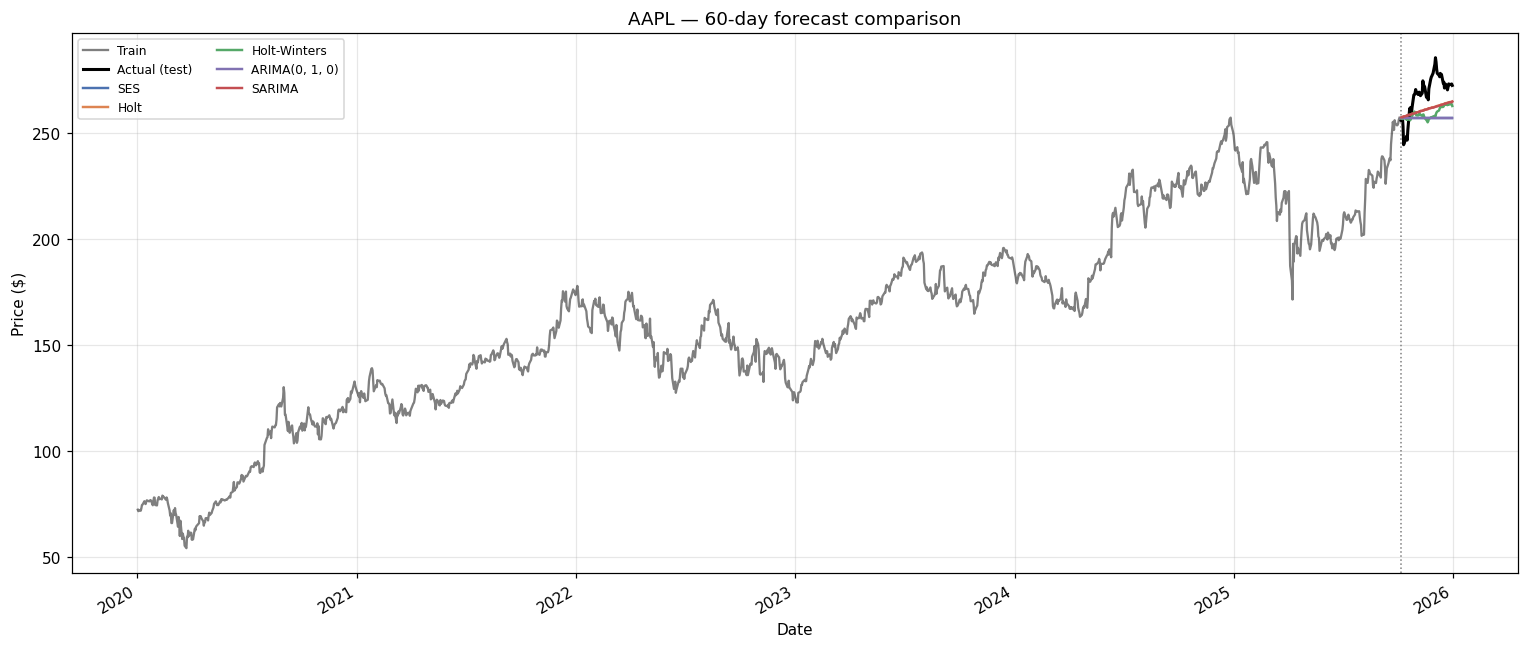

In [14]:
# VISUALISE FORECASTS
fig, ax = plt.subplots(figsize=(14, 6))
train.plot(ax=ax, label="Train", color="black", alpha=0.5)
test.plot(ax=ax,  label="Actual (test)", color="black", lw=2)

colors = ["#4C72B0", "#DD8452", "#55A868", "#8172B2", "#C44E52", "#937860"]
for (name, fc), c in zip(forecasts.items(), colors):
    ax.plot(test.index, np.asarray(fc), label=name, color=c, lw=1.6)

ax.axvline(test.index[0], color="grey", ls=":", lw=1)
ax.set_title(f"{TICKER} — 60-day forecast comparison")
ax.set_xlabel("Date"); ax.set_ylabel("Price ($)")
ax.legend(fontsize=8, ncol=2); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ts_forecast.png", bbox_inches="tight")
plt.show()

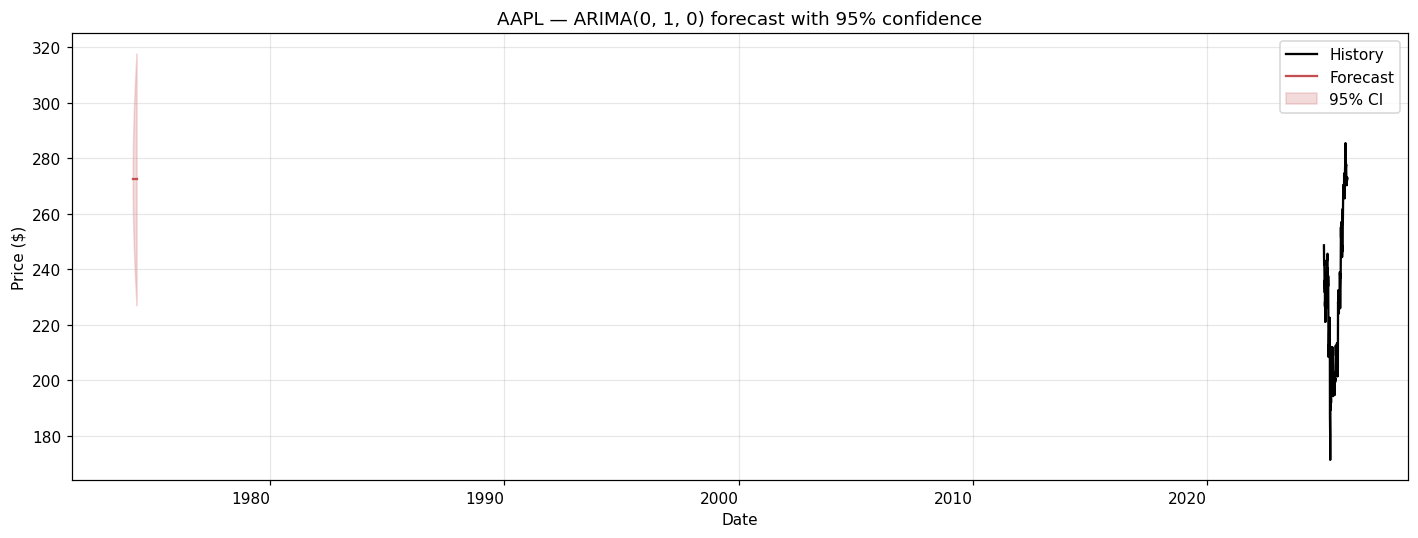


💾 Saved:
   • ts_raw.png
   • ts_decomposition.png
   • ts_acf_pacf.png
   • ts_smoothing.png
   • ts_forecast.png
   • ts_arima_forecast.png
   • ts_metrics.csv


In [15]:
#  ARIMA FORECAST WITH CONFIDENCE INTERVALS
# Refit ARIMA on the FULL series, then forecast 60 days into the future
final_arima = ARIMA(series, order=best_order).fit()
future = final_arima.get_forecast(steps=HORIZON)
mean_fc = future.predicted_mean
ci = future.conf_int(alpha=0.05)

fig, ax = plt.subplots(figsize=(13, 5))
series.iloc[-250:].plot(ax=ax, label="History", color="black")
mean_fc.plot(ax=ax, label="Forecast", color="#C44E52")
ax.fill_between(ci.index, ci.iloc[:, 0], ci.iloc[:, 1],
                color="#C44E52", alpha=0.20, label="95% CI")
ax.set_title(f"{TICKER} — ARIMA{best_order} forecast with 95% confidence")
ax.set_xlabel("Date"); ax.set_ylabel("Price ($)")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("ts_arima_forecast.png", bbox_inches="tight")
plt.show()

print("\n💾 Saved:")
for f in ["ts_raw.png", "ts_decomposition.png", "ts_acf_pacf.png",
          "ts_smoothing.png", "ts_forecast.png", "ts_arima_forecast.png",
          "ts_metrics.csv"]:
    print(f"   • {f}")